# Telco Customer Churn - 03. Model Training
Steps 11-13: baseline, train multiple models, tune models.

## 0. Setup (recap)
Reloads the data and re-derives earlier decisions, so this notebook can run on its own.

In [1]:
import os, hashlib, warnings, platform, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             balanced_accuracy_score, RocCurveDisplay, PrecisionRecallDisplay, brier_score_loss)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.base import clone
from scipy.stats import loguniform, randint

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50, "display.width", 160)

In [2]:
from google.colab import files

uploaded = files.upload()
EXPECTED_FILE = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
assert EXPECTED_FILE in uploaded, f"Please upload {EXPECTED_FILE}"

DATA_PATH = Path(EXPECTED_FILE)
sha = hashlib.sha256(open(DATA_PATH, "rb").read()).hexdigest()
raw = pd.read_csv(DATA_PATH)

ADDONS = ["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]
df0 = raw.copy()
df0["TotalCharges"] = pd.to_numeric(df0.TotalCharges.astype(str).str.strip().replace("", np.nan), errors="coerce").fillna(0.0)
df0["ChurnFlag"] = (df0.Churn == "Yes").astype(int)

y = df0["ChurnFlag"]
X = df0.drop(columns=["customerID", "Churn", "ChurnFlag"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Recap loaded. Train:", X_train.shape, "Test:", X_test.shape, "| SHA-256:", sha)

Recap loaded. Train: (5634, 19) Test: (1409, 19) | SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a


In [3]:
SIMPLIFY = ["MultipleLines"] + ADDONS
NUM_BASE = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
CAT_BASE = ["gender","Partner","Dependents","PhoneService","MultipleLines","InternetService"] + ADDONS + \
           ["Contract","PaperlessBilling","PaymentMethod"]

def make_features(X, extras=(), drop_gender=False):
    X = X.copy()
    for c in SIMPLIFY:
        X[c] = X[c].replace({"No internet service": "No", "No phone service": "No"})
    if "n_addons" in extras:
        X["n_addons"] = (X[ADDONS] == "Yes").sum(axis=1)
    if "autopay" in extras:
        X["autopay"] = X["PaymentMethod"].str.contains("automatic").astype(int)
    if "charge_gap" in extras:
        t = X["tenure"].where(X["tenure"] > 0)
        X["charge_gap"] = (X["MonthlyCharges"] - X["TotalCharges"] / t).fillna(0.0)
    if drop_gender:
        X = X.drop(columns=["gender"])
    return X

def build_pipeline(clf, extras=(), drop_gender=False, scale=True):
    num = NUM_BASE + [e for e in ("n_addons", "charge_gap", "autopay") if e in extras]
    cat = [c for c in CAT_BASE if not (drop_gender and c == "gender")]
    prep = ColumnTransformer(
        [("num", StandardScaler() if scale else "passthrough", num),
         ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat)],
        remainder="drop", verbose_feature_names_out=False)
    steps = [("fe", FunctionTransformer(make_features, kw_args={"extras": tuple(extras), "drop_gender": drop_gender})),
             ("prep", prep), ("clf", clf)]
    return Pipeline(steps)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
INNER = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "precision": "precision", "recall": "recall", "f1": "f1"}
def run_cv(model, X, y, scoring=SCORING):
    res = cross_validate(model, X, y, cv=CV, scoring=scoring, n_jobs=-1)
    return {k[5:]: v for k, v in res.items() if k.startswith("test_")}
def ms(v): return f"{np.mean(v):.3f} \u00b1 {np.std(v):.3f}"
print("Pipeline helper functions ready.")

Pipeline helper functions ready.


In [4]:
# Recap of the feature/imbalance decisions made in 02_Preprocessing.ipynb (re-derived here so this notebook stands alone)
configs = {"base": ((), False), "+n_addons": (("n_addons",), False), "+autopay": (("autopay",), False),
           "+charge_gap": (("charge_gap",), False), "drop gender": ((), True)}
two = {"LogReg": (lambda: LogisticRegression(max_iter=2000), True),
       "HistGB": (lambda: HistGradientBoostingClassifier(random_state=SEED, max_iter=150, learning_rate=0.05), False)}
abl = {}
for cname, (ex, dg) in configs.items():
    for mname, (mk, sc) in two.items():
        abl[(cname, mname)] = run_cv(build_pipeline(mk(), ex, dg, sc), X_train, y_train, {"pr_auc": "average_precision"})
EXTRAS = tuple(e for e, k in [("n_addons", "+n_addons"), ("autopay", "+autopay"), ("charge_gap", "+charge_gap")]
               if all(abl[(k, m)]["pr_auc"].mean() > abl[("base", m)]["pr_auc"].mean() for m in two))
DROP_GENDER = all(abl[("drop gender", m)]["pr_auc"].mean() >= abl[("base", m)]["pr_auc"].mean() - 0.001 for m in two)

variants = {"none": build_pipeline(LogisticRegression(max_iter=2000), EXTRAS, DROP_GENDER, True),
            "balanced": build_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"), EXTRAS, DROP_GENDER, True)}
imb = {n: run_cv(m, X_train, y_train) for n, m in variants.items()}
USE_WEIGHTS = imb["balanced"]["pr_auc"].mean() > imb["none"]["pr_auc"].mean() + imb["none"]["pr_auc"].std()
CLASS_WEIGHT = "balanced" if USE_WEIGHTS else None

def all_models():
    cw = CLASS_WEIGHT
    return {
     "Dummy":        build_pipeline(DummyClassifier(strategy="prior"), EXTRAS, DROP_GENDER, False),
     "LogReg":       build_pipeline(LogisticRegression(max_iter=2000, class_weight=cw), EXTRAS, DROP_GENDER, True),
     "DecisionTree": build_pipeline(DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, class_weight=cw, random_state=SEED), EXTRAS, DROP_GENDER, False),
     "RandomForest": build_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight=cw, random_state=SEED, n_jobs=-1), EXTRAS, DROP_GENDER, False),
     "HistGB":       build_pipeline(HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, class_weight=cw, random_state=SEED), EXTRAS, DROP_GENDER, False),
    }
print("Kept features:", EXTRAS, "| Drop gender:", DROP_GENDER, "| Class weight:", CLASS_WEIGHT)

Kept features: ('n_addons',) | Drop gender: True | Class weight: None


## 11. Build Baseline
A Dummy classifier (majority class) sets the floor; logistic regression is the sensible baseline.

In [5]:
def all_models():
    cw = CLASS_WEIGHT
    return {
     "Dummy":        build_pipeline(DummyClassifier(strategy="prior"), EXTRAS, DROP_GENDER, False),
     "LogReg":       build_pipeline(LogisticRegression(max_iter=2000, class_weight=cw), EXTRAS, DROP_GENDER, True),
     "DecisionTree": build_pipeline(DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, class_weight=cw, random_state=SEED), EXTRAS, DROP_GENDER, False),
     "RandomForest": build_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight=cw, random_state=SEED, n_jobs=-1), EXTRAS, DROP_GENDER, False),
     "HistGB":       build_pipeline(HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, class_weight=cw, random_state=SEED), EXTRAS, DROP_GENDER, False),
    }

baseline_cv = run_cv(all_models()["Dummy"], X_train, y_train, {"roc_auc":"roc_auc","pr_auc":"average_precision","accuracy":"accuracy"})
print("Dummy baseline (majority class):")
print("  ROC-AUC :", ms(baseline_cv["roc_auc"]))
print("  PR-AUC  :", ms(baseline_cv["pr_auc"]))
print("  Accuracy:", ms(baseline_cv["accuracy"]), " (= always predicting 'no churn')")

Dummy baseline (majority class):
  ROC-AUC : 0.500 ± 0.000
  PR-AUC  : 0.265 ± 0.000
  Accuracy: 0.735 ± 0.000  (= always predicting 'no churn')


## 12. Train Multiple ML Models
Run the same 5-fold CV for every model, with default hyperparameters.

In [6]:
untuned = {n: run_cv(m, X_train, y_train, {"roc_auc":"roc_auc","pr_auc":"average_precision","accuracy":"accuracy",
                                            "precision":"precision","recall":"recall","f1":"f1"})
           for n, m in all_models().items()}
tbl = pd.DataFrame({n: {k: ms(v[k]) for k in ["roc_auc","pr_auc","accuracy","precision","recall","f1"]} for n, v in untuned.items()}).T
display(tbl)

,roc_auc,pr_auc,accuracy,precision,recall,f1
Dummy,0.500 ± 0.000,0.265 ± 0.000,0.735 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
LogReg,0.846 ± 0.013,0.661 ± 0.019,0.803 ± 0.013,0.655 ± 0.029,0.544 ± 0.041,0.594 ± 0.031
DecisionTree,0.829 ± 0.011,0.613 ± 0.023,0.790 ± 0.010,0.624 ± 0.024,0.527 ± 0.041,0.570 ± 0.027
RandomForest,0.844 ± 0.010,0.658 ± 0.022,0.800 ± 0.012,0.666 ± 0.035,0.498 ± 0.021,0.569 ± 0.023
HistGB,0.836 ± 0.008,0.644 ± 0.022,0.799 ± 0.013,0.650 ± 0.035,0.526 ± 0.022,0.581 ± 0.025


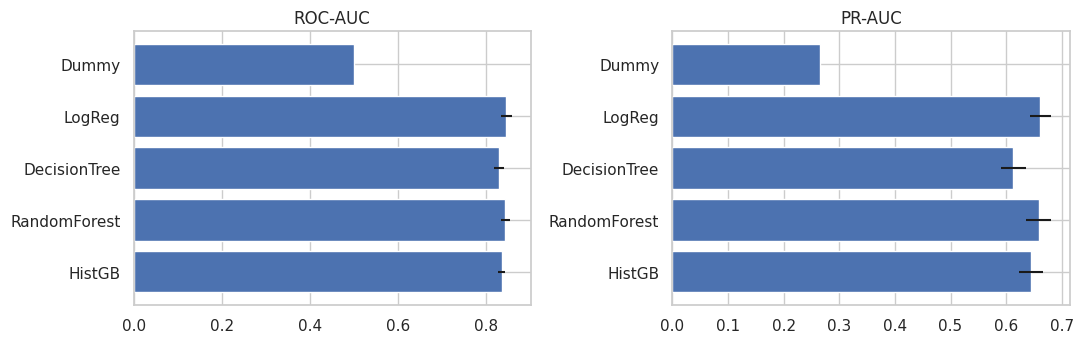

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, k, t in zip(axes, ["roc_auc", "pr_auc"], ["ROC-AUC", "PR-AUC"]):
    ax.barh(list(untuned), [untuned[n][k].mean() for n in untuned], xerr=[untuned[n][k].std() for n in untuned], color="#4C72B0")
    ax.set_title(t); ax.invert_yaxis()
plt.tight_layout(); plt.show()

## 13. Tune Models
RandomizedSearchCV for all four models, evaluated with nested cross-validation (tuning happens only inside training folds).

In [8]:
SPACES = {
 "LogReg":       {"clf__C": loguniform(1e-3, 1e2)},
 "DecisionTree": {"clf__max_depth": randint(2, 12), "clf__min_samples_leaf": randint(5, 100), "clf__criterion": ["gini", "entropy"]},
 "RandomForest": {"clf__n_estimators": randint(150, 400), "clf__max_depth": randint(4, 16), "clf__min_samples_leaf": randint(2, 30),
                  "clf__max_features": ["sqrt", 0.3, 0.5]},
 "HistGB":       {"clf__learning_rate": loguniform(0.02, 0.2), "clf__max_iter": randint(80, 300), "clf__max_leaf_nodes": randint(6, 32),
                  "clf__min_samples_leaf": randint(10, 80), "clf__l2_regularization": loguniform(1e-3, 10)},
}
N_ITER = {"LogReg": 10, "DecisionTree": 15, "RandomForest": 12, "HistGB": 12}
TUNE = list(SPACES)

def make_search(name, cv=INNER):
    return RandomizedSearchCV(all_models()[name], SPACES[name], n_iter=N_ITER[name], scoring="average_precision",
                              cv=cv, random_state=SEED, n_jobs=-1, refit=True)

In [9]:
nested, t0 = {}, time.time()
for name in TUNE:
    res = cross_validate(make_search(name), X_train, y_train, cv=CV, scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"}, n_jobs=1)
    nested[name] = {"roc_auc": res["test_roc_auc"], "pr_auc": res["test_pr_auc"]}
    print(f"{name:13s} nested PR-AUC {ms(nested[name]['pr_auc'])} | ROC-AUC {ms(nested[name]['roc_auc'])}   ({time.time()-t0:.0f}s elapsed)")

LogReg        nested PR-AUC 0.661 ± 0.019 | ROC-AUC 0.846 ± 0.013   (7s elapsed)


DecisionTree  nested PR-AUC 0.622 ± 0.026 | ROC-AUC 0.823 ± 0.013   (18s elapsed)


RandomForest  nested PR-AUC 0.664 ± 0.019 | ROC-AUC 0.847 ± 0.010   (176s elapsed)


HistGB        nested PR-AUC 0.659 ± 0.019 | ROC-AUC 0.846 ± 0.012   (231s elapsed)


In [10]:
order = ["LogReg", "DecisionTree", "RandomForest", "HistGB"]
best_name = max(TUNE, key=lambda n: nested[n]["pr_auc"].mean())
se_best = nested[best_name]["pr_auc"].std() / np.sqrt(len(nested[best_name]["pr_auc"]))
eligible = [n for n in order if nested[n]["pr_auc"].mean() >= nested[best_name]["pr_auc"].mean() - se_best]
FINAL_NAME = eligible[0]
print("Best mean PR-AUC:", best_name, "| Within 1 SE:", eligible, "| Chosen (simplest eligible):", FINAL_NAME)

Best mean PR-AUC: RandomForest | Within 1 SE: ['LogReg', 'RandomForest', 'HistGB'] | Chosen (simplest eligible): LogReg


In [11]:
final_search = make_search(FINAL_NAME, cv=CV)
final_search.fit(X_train, y_train)
final_model = final_search.best_estimator_
print("Final model:", FINAL_NAME)
print("Best hyper-parameters:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in final_search.best_params_.items()})

Final model: LogReg
Best hyper-parameters: {'clf__C': np.float64(4.5706)}
